# Aula 06 — Prática · Avaliar modelos

Nesta aula: treinamos dois modelos sobre a base curada — um classificador de risco de baixa produção e um regressor de produtividade — e lemos o resultado de cada um: matriz de confusão, curva ROC, predito–real, resíduos e a importância das variáveis.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (confusion_matrix, mean_absolute_error,
                             mean_squared_error, r2_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit

plt.rcParams.update({
    "figure.figsize": (10, 5.6),
    "figure.dpi": 110,
    "font.size": 13,
    "axes.grid": True, "grid.alpha": 0.3,
})

AZUL, LARANJA, CINZA = "#0173B2", "#DE8F05", "#949494"   # paleta "colorblind" do seaborn
SEMENTE = 42

# RAIZ = a pasta uma acima da pasta deste notebook: contém base_curada.csv, environment.yml
# e as pastas aula-XX. Encontrada subindo a partir do diretório de trabalho.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "base_curada.csv").is_file())
BASE = RAIZ / "base_curada.csv"
SAIDAS = Path("saidas")   # relativa à pasta do notebook; criada se não existir
SAIDAS.mkdir(parents=True, exist_ok=True)


def salvar(figura, nome):
    """Guarda a figura em disco. Não aparece na tela."""
    figura.savefig(SAIDAS / nome, dpi=600, bbox_inches="tight")


def br(x, casas=2):
    """Formata número no padrão brasileiro (vírgula decimal), para texto dentro da figura."""
    return f"{x:.{casas}f}".replace(".", ",")

## A base, pronta para virar modelo

In [2]:
dados = pd.read_csv(BASE)
dados.head(3)

,ano,regiao,cultura,estacao,area_ha,producao_t,produtividade_t_ha,produtividade_informada,chuva_mm,fertilizante_kg_ha,defensivo_kg_ha
0,1997,Assam,Milho,Monção,19216.0,14721,0.766080,0.615652,2051.4,95.17,0.31
1,1997,Assam,Arroz,Outono,607358.0,398311,0.655809,0.780870,2051.4,95.17,0.31
2,1997,Assam,Arroz,Verão,174974.0,209623,1.198024,1.060435,2051.4,95.17,0.31


## Separar treino e teste sem vazar a região

In [3]:
grupo = dados["regiao"] + "_" + dados["ano"].astype(str)
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEMENTE)
idx_tr, idx_te = next(gss.split(dados, groups=grupo))

display(pd.DataFrame({
    "linhas": [len(idx_tr), len(idx_te)],
    "grupos região-ano distintos": [grupo.iloc[idx_tr].nunique(), grupo.iloc[idx_te].nunique()],
}, index=["treino", "teste"]))

,linhas,grupos região-ano distintos
treino,2698,490
teste,970,164


## O alvo: baixa produção, dentro da própria cultura

In [4]:
# calculado só no treino, para não vazar a distribuição de teste na definição do rótulo
limiar_por_cultura = (
    dados.iloc[idx_tr].groupby("cultura")["produtividade_t_ha"].quantile(0.25)
)
dados["risco_baixa_producao"] = (
    dados["produtividade_t_ha"] < dados["cultura"].map(limiar_por_cultura)
).astype(int)

display(limiar_por_cultura.round(2).to_frame("limiar (t/ha, p25 no treino)"))
print(f"Positivos na base inteira: {dados['risco_baixa_producao'].mean()*100:.1f}%")

,"limiar (t/ha, p25 no treino)"
cultura,
Arroz,1.78
Feijão-moth,0.27
Feijão-mungo,0.31
Feijão-urad,0.38
Milho,1.55


Positivos na base inteira: 25.6%


## Montar as features — o que fica de fora importa mais do que o que entra

In [5]:
dados["regiao_cod"] = dados["regiao"].astype("category").cat.codes

# producao_t, produtividade_t_ha e produtividade_informada ficam de fora: são elas
# que definem o alvo (a última correlaciona 0,959 com a produtividade recalculada).
colunas_numericas = ["regiao_cod", "ano", "area_ha", "chuva_mm", "fertilizante_kg_ha", "defensivo_kg_ha"]
dummies = pd.get_dummies(dados[["cultura", "estacao"]], prefix=["cultura", "estacao"])
X = pd.concat([dados[colunas_numericas], dummies], axis=1)
Xtr, Xte = X.iloc[idx_tr], X.iloc[idx_te]

display(pd.Series({"linhas": len(X), "colunas (features)": len(X.columns)}).to_frame("shape"))

,shape
linhas,3668
colunas (features),17


## Dois modelos, treinados ao vivo

In [6]:
ytr, yte = dados["risco_baixa_producao"].iloc[idx_tr], dados["risco_baixa_producao"].iloc[idx_te]
# max_depth raso de propósito: sem limite, a floresta memoriza a "impressão digital"
# de chuva/manejo da célula região-ano, e o desempenho deixa de ensinar nada.
clf = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=SEMENTE, n_jobs=-1)
clf.fit(Xtr, ytr)
scores = clf.predict_proba(Xte)[:, 1]

yrtr, yrte = dados["produtividade_t_ha"].iloc[idx_tr], dados["produtividade_t_ha"].iloc[idx_te]
reg = RandomForestRegressor(n_estimators=300, max_depth=4, random_state=SEMENTE, n_jobs=-1)
reg.fit(Xtr, yrtr)
pred = reg.predict(Xte)

## A matriz de confusão, duas leituras

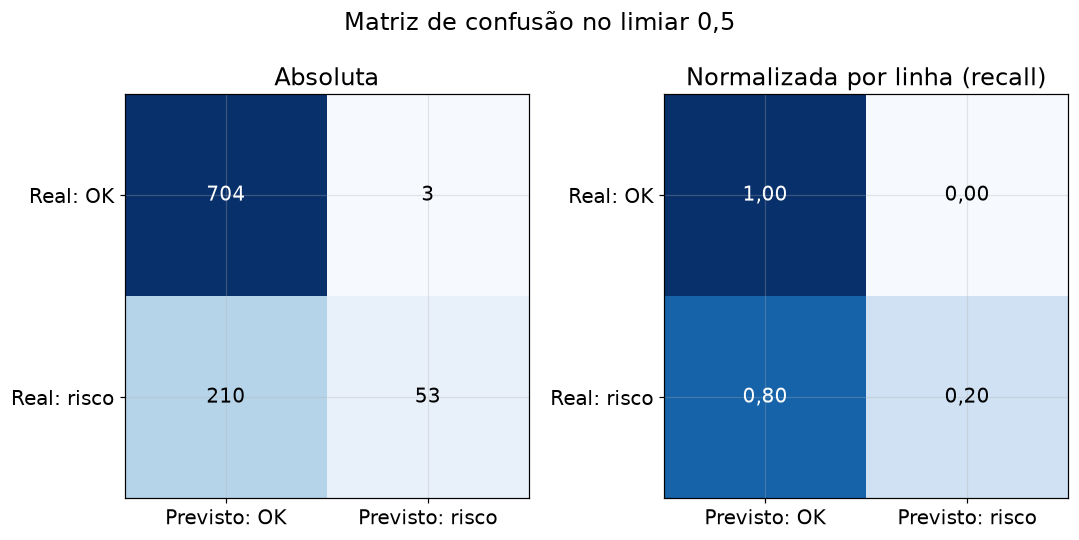

In [7]:
cm = confusion_matrix(yte, (scores >= 0.5).astype(int))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, eixos = plt.subplots(1, 2, figsize=(10, 5))
painel = [(cm, "d", "Absoluta"), (cm_norm, "f", "Normalizada por linha (recall)")]
for eixo, (matriz, formato, titulo) in zip(eixos, painel):
    eixo.imshow(matriz, cmap="Blues", vmin=0)
    for i in range(2):
        for j in range(2):
            valor = matriz[i, j]
            texto = f"{valor:d}" if formato == "d" else br(valor)
            eixo.text(j, i, texto, ha="center", va="center", fontsize=13,
                       color="white" if valor > matriz.max() * 0.5 else "black")
    eixo.set_xticks([0, 1], ["Previsto: OK", "Previsto: risco"])
    eixo.set_yticks([0, 1], ["Real: OK", "Real: risco"])
    eixo.set_title(titulo)
fig.suptitle("Matriz de confusão no limiar 0,5")
fig.tight_layout()
salvar(fig, "f6-1-matriz-confusao.png")
plt.show()

## Números por trás dos quadrados

In [8]:
recall_5 = cm[1, 1] / cm[1].sum()
precisao_5 = cm[1, 1] / cm[:, 1].sum()
acuracia_5 = (cm[0, 0] + cm[1, 1]) / cm.sum()

display(pd.Series({"recall": recall_5, "precisão": precisao_5, "acurácia": acuracia_5})
        .round(3).to_frame("limiar 0,5"))

,"limiar 0,5"
recall,0.202
precisão,0.946
acurácia,0.780


## O corte é decisão, não propriedade do modelo

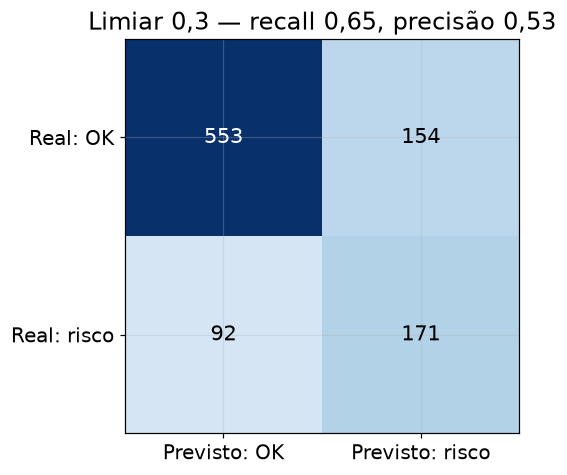

In [9]:
# reaplica o corte sobre os scores já calculados — nenhum modelo é retreinado
cm3 = confusion_matrix(yte, (scores >= 0.3).astype(int))
recall_3 = cm3[1, 1] / cm3[1].sum()
precisao_3 = cm3[1, 1] / cm3[:, 1].sum()

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(cm3, cmap="Blues", vmin=0)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm3[i, j]:d}", ha="center", va="center", fontsize=14,
                 color="white" if cm3[i, j] > cm3.max() * 0.5 else "black")
ax.set_xticks([0, 1], ["Previsto: OK", "Previsto: risco"])
ax.set_yticks([0, 1], ["Real: OK", "Real: risco"])
ax.set_title(f"Limiar 0,3 — recall {br(recall_3)}, precisão {br(precisao_3)}")
fig.tight_layout()
salvar(fig, "f6-2-matriz-limiar-03.png")
plt.show()

## O formato que resume o desempenho

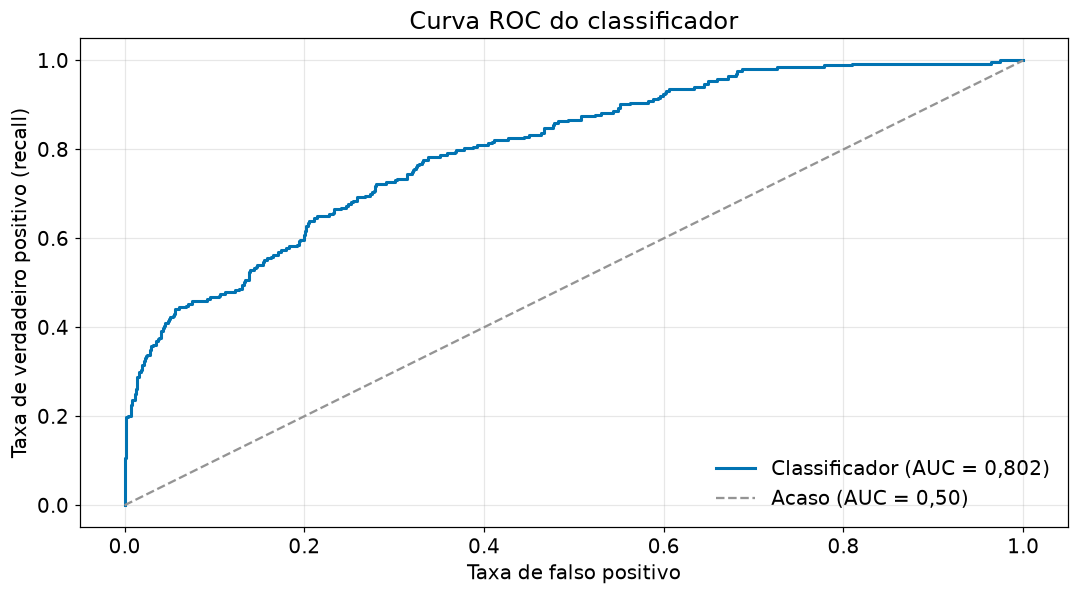

In [10]:
fpr, tpr, _ = roc_curve(yte, scores)
auc = roc_auc_score(yte, scores)

fig, ax = plt.subplots()
ax.plot(fpr, tpr, color=AZUL, linewidth=2, label=f"Classificador (AUC = {br(auc, 3)})")
ax.plot([0, 1], [0, 1], color=CINZA, linestyle="--", label="Acaso (AUC = 0,50)")
ax.set_xlabel("Taxa de falso positivo")
ax.set_ylabel("Taxa de verdadeiro positivo (recall)")
ax.set_title("Curva ROC do classificador")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
salvar(fig, "f6-3-curva-roc.png")
plt.show()

## O regressor: onde acerta, onde escorrega

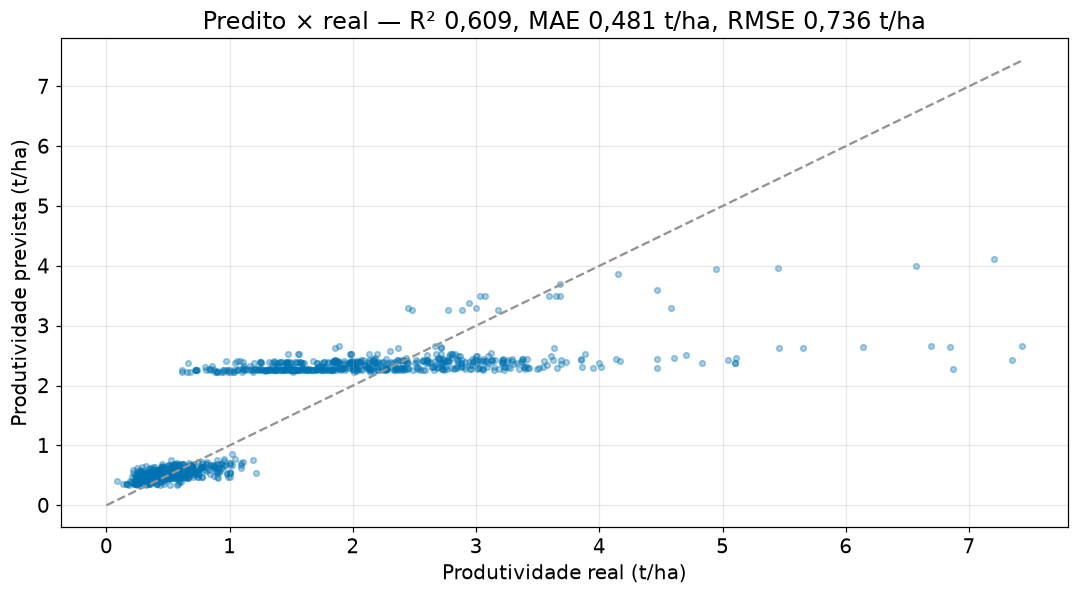

In [11]:
r2 = r2_score(yrte, pred)
mae = mean_absolute_error(yrte, pred)
rmse = mean_squared_error(yrte, pred) ** 0.5

fig, ax = plt.subplots()
ax.scatter(yrte, pred, s=14, color=AZUL, alpha=0.35)
limite = max(yrte.max(), pred.max())
ax.plot([0, limite], [0, limite], color=CINZA, linestyle="--")
ax.set_xlabel("Produtividade real (t/ha)")
ax.set_ylabel("Produtividade prevista (t/ha)")
ax.set_title(f"Predito × real — R² {br(r2, 3)}, MAE {br(mae, 3)} t/ha, RMSE {br(rmse, 3)} t/ha")
fig.tight_layout()
salvar(fig, "f6-4-predito-real.png")
plt.show()

## O erro tem padrão?

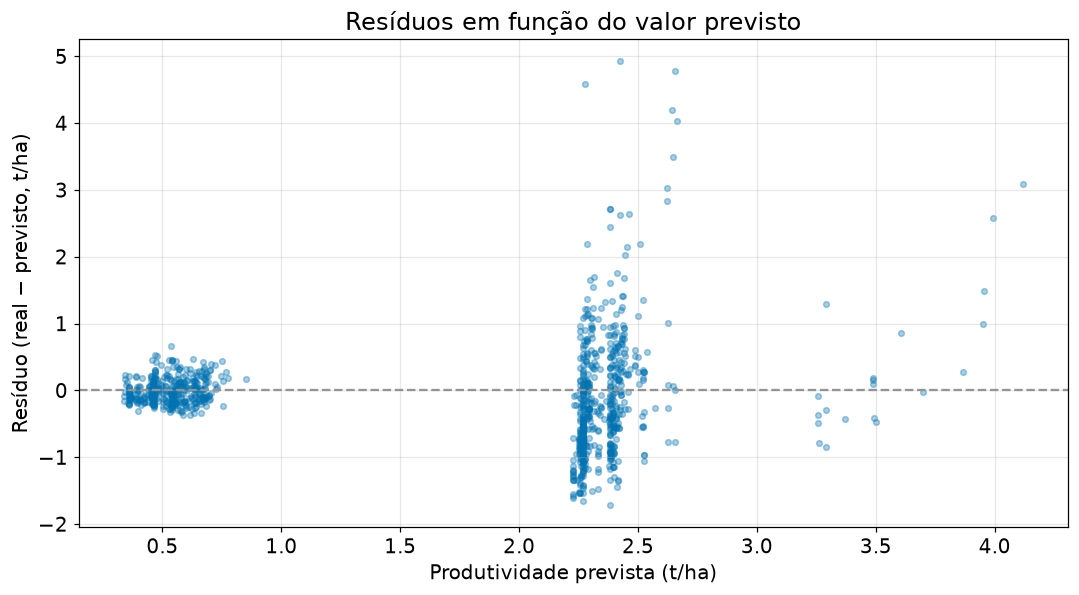

In [12]:
residuos = yrte.values - pred

fig, ax = plt.subplots()
ax.scatter(pred, residuos, s=14, color=AZUL, alpha=0.35)
ax.axhline(0, color=CINZA, linestyle="--")
ax.set_xlabel("Produtividade prevista (t/ha)")
ax.set_ylabel("Resíduo (real − previsto, t/ha)")
ax.set_title("Resíduos em função do valor previsto")
fig.tight_layout()
salvar(fig, "f6-5-residuos.png")
plt.show()

## Antes do gráfico, os números

In [13]:
importancias = pd.Series(clf.feature_importances_, index=X.columns).sort_values(ascending=False)
display(importancias.head(5).round(3).to_frame("importância"))

,importância
regiao_cod,0.234
area_ha,0.145
ano,0.118
estacao_Outono,0.105
chuva_mm,0.095


## Em quem o classificador mais confia

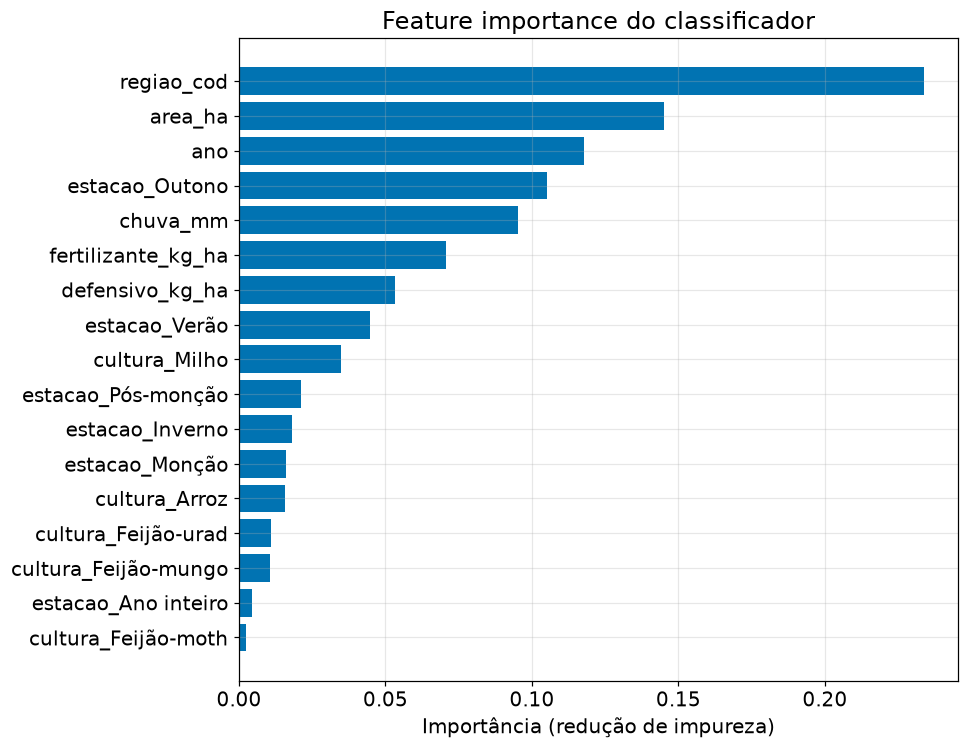

In [14]:
ordenadas = importancias.sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(ordenadas.index, ordenadas.values, color=AZUL)
ax.set_xlabel("Importância (redução de impureza)")
ax.set_title("Feature importance do classificador")
fig.tight_layout()
salvar(fig, "f6-6-feature-importance.png")
plt.show()

## O que fica salvo para as próximas aulas

In [15]:
pd.DataFrame({"real": yte.values, "score": scores}).to_csv(SAIDAS / "scores_teste.csv", index=False)
(importancias.rename("importancia").rename_axis("feature")
             .reset_index().to_csv(SAIDAS / "importancias.csv", index=False))

## O que levamos daqui

Dois modelos, quatro leituras: matriz de confusão e curva ROC no classificador, predito×real e resíduos no regressor — e uma pergunta que atravessa as duas, a mesma que a teórica anterior levantou: o modelo aprendeu um padrão de verdade, ou só decorou o dado? Os scores e a importância ficam salvos para as próximas aulas reaproveitarem, sem retreinar nada.